# Escenario extendido: los 4 modelos con variables recuperadas

Requiere haber ejecutado `notebooks/etl/01_features_ext.ipynb` para generar `data/processed/airprice_features_ext.csv`.

**Qué cambia respecto a geo:** se añaden variables del original que el ETL baseline descartó (review scores, disponibilidad, portafolio del host, amenidades, etc.) y geo adicional (densidad, distancias a estaciones/landmarks, K-Means k=5/8/10).

**Qué se mantiene:** mismo split, misma semilla y mismas métricas (`src.utils.evaluar_modelo` + métricas ordinales).

**Imputación:** el dataset extendido tiene nulos en review scores y fechas; el preprocesador imputa numéricas con la mediana y agrega indicadores de faltante. Los árboles también podrían manejar nulos, pero la imputación mantiene el pipeline homogéneo con el modelo ordinal.

**Target encoding:** no se usa por defecto en este notebook. Se evalúa en `02_tuning_extendido.ipynb` para no mezclar el efecto de las variables nuevas con el del codificador.

In [1]:
import sys
sys.path.append('../..')

import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

from src.model_features import (
    PARAMS_EXT,
    construir_modelo_features,
    evaluar_modelo_ordinal,
    importancia_variables,
    metricas_a_fila,
)
from src.model_ordinal import codificar_y, decodificar_y
from src.preprocessing_features import FEATURES_EXT_PATH, preparar_dataset_features
from src.utils import (
    CLASES,
    REPORTS_DIR,
    SEED,
    cargar_dataset,
    fijar_semilla,
    guardar_modelo,
    split_estratificado,
)

sns.set_theme(style='whitegrid')
fijar_semilla(SEED)
print('Semilla:', SEED)
print('Dataset:', FEATURES_EXT_PATH)

Semilla: 42
Dataset: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\data\processed\airprice_features_ext.csv


In [2]:
df = preparar_dataset_features(
    cargar_dataset(FEATURES_EXT_PATH),
    descartar_baseline=False,
)
print('Filas:', df.shape[0], 'Columnas:', df.shape[1])

X_train, X_val, X_test, y_train, y_val, y_test = split_estratificado(
    df,
    target='price_range',
    excluir=['price_clean', 'id'],
    seed=SEED,
)
print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)

geo_ext = [
    c for c in X_train.columns
    if c.startswith('distancia_') or c.startswith('cluster_zona')
]
print('Features geo extendidas:', geo_ext)
print('¿price_clean en X_train?', 'price_clean' in X_train.columns)
print('¿price en X_train?', 'price' in X_train.columns)

Filas: 61617 Columnas: 152
Train: (43131, 151) Val: (9243, 151) Test: (9243, 151)
Features geo extendidas: ['distancia_centro_km', 'distancia_heathrow_km', 'distancia_kings_cross_km', 'distancia_hyde_park_km', 'distancia_canary_wharf_km', 'cluster_zona', 'distancia_min_poi_km', 'distancia_metro_km', 'distancia_landmark_km', 'distancia_aeropuerto_km', 'distancia_vecino_km', 'cluster_zona_k5', 'cluster_zona_k8', 'cluster_zona_k10']
¿price_clean en X_train? False
¿price en X_train? False


In [3]:
resultados = []
modelos_entrenados = {}

for nombre in ['random_forest', 'xgboost', 'lightgbm', 'ordinal_logistic']:
    print('=' * 70)
    print('Entrenando:', nombre)
    params = dict(PARAMS_EXT[nombre])
    modelo = construir_modelo_features(
        nombre,
        X_train,
        imputar=True,
        target_encoding=None,
        **params,
    )

    if nombre in ('xgboost', 'ordinal_logistic'):
        modelo.fit(X_train, codificar_y(y_train))
        pred_val = decodificar_y(modelo.predict(X_val))
        pred_test = decodificar_y(modelo.predict(X_test))
    else:
        modelo.fit(X_train, y_train)
        pred_val = modelo.predict(X_val)
        pred_test = modelo.predict(X_test)

    met_val = evaluar_modelo_ordinal(y_val, pred_val)
    met_test = evaluar_modelo_ordinal(y_test, pred_test)
    print('Validación:', {k: round(v, 4) for k, v in met_val.items() if k != 'matriz_confusion'})
    print('Test:', {k: round(v, 4) for k, v in met_test.items() if k != 'matriz_confusion'})

    modelos_entrenados[nombre] = modelo
    resultados.append(
        metricas_a_fila(
            f'{nombre}_ext',
            met_test,
            escenario='extendido',
            **params,
        )
    )

    pd.DataFrame([resultados[-1]]).to_csv(
        REPORTS_DIR / f'{nombre}_ext_metricas.csv', index=False
    )

    ConfusionMatrixDisplay(
        met_test['matriz_confusion'], display_labels=CLASES
    ).plot(cmap='Blues', values_format='d')
    plt.title(f'{nombre} + extendido - test')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(
        REPORTS_DIR / f'{nombre}_ext_matriz_confusion.png',
        dpi=150,
        bbox_inches='tight',
    )
    plt.close()

    try:
        importancia = importancia_variables(modelo)
        importancia.to_csv(
            REPORTS_DIR / f'{nombre}_ext_importancia.csv', index=False
        )
    except Exception as error:
        print('No se pudo calcular importancia:', error)

    ruta = guardar_modelo(modelo, f'{nombre}_ext')
    print('Modelo guardado en:', ruta)

print('=' * 70)
print('Modelos entrenados:', list(modelos_entrenados))

Entrenando: random_forest
Validación: {'accuracy': 0.7147, 'balanced_accuracy': 0.7143, 'f1_macro': 0.7128, 'f1_weighted': 0.7131, 'accuracy_adjacent': 0.9719, 'mae_ordinal': 0.3186, 'qwk': 0.8436}
Test: {'accuracy': 0.7117, 'balanced_accuracy': 0.7114, 'f1_macro': 0.7101, 'f1_weighted': 0.7104, 'accuracy_adjacent': 0.9713, 'mae_ordinal': 0.3232, 'qwk': 0.8393}
Modelo guardado en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\models\random_forest_ext.joblib
Entrenando: xgboost
Validación: {'accuracy': 0.7229, 'balanced_accuracy': 0.7226, 'f1_macro': 0.7224, 'f1_weighted': 0.7227, 'accuracy_adjacent': 0.9787, 'mae_ordinal': 0.3008, 'qwk': 0.8591}
Test: {'accuracy': 0.7242, 'balanced_accuracy': 0.7239, 'f1_macro': 0.7239, 'f1_weighted': 0.7242, 'accuracy_adjacent': 0.9788, 'mae_ordinal': 0.3007, 'qwk': 0.8568}
Modelo guardado en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\models\xgboost_ext.joblib
Entrenando: lightgbm
Validación: {'accuracy': 0.7308, 'b

d:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\.venv\Lib\site-packages\mord\threshold_based.py:132: OptimizeWarning: Unknown solver options: disp
  sol = optimize.minimize(obj_margin, x0, method='L-BFGS-B',


Validación: {'accuracy': 0.6758, 'balanced_accuracy': 0.6755, 'f1_macro': 0.6786, 'f1_weighted': 0.6789, 'accuracy_adjacent': 0.9791, 'mae_ordinal': 0.3472, 'qwk': 0.8371}
Test: {'accuracy': 0.6738, 'balanced_accuracy': 0.6736, 'f1_macro': 0.6768, 'f1_weighted': 0.677, 'accuracy_adjacent': 0.9773, 'mae_ordinal': 0.3518, 'qwk': 0.832}
Modelo guardado en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\models\ordinal_logistic_ext.joblib
Modelos entrenados: ['random_forest', 'xgboost', 'lightgbm', 'ordinal_logistic']


,modelo,escenario,n_estimators,max_depth,max_features,min_samples_leaf,accuracy,balanced_accuracy,f1_macro,f1_weighted,...,mae_ordinal,qwk,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda,num_leaves,min_child_samples,alpha
2,lightgbm_ext,extendido,400.0,NaN,NaN,NaN,0.729741,0.729438,0.728812,0.729075,...,0.295575,0.859333,0.05,0.8,0.8,NaN,1.0,63.0,20.0,NaN
1,xgboost_ext,extendido,300.0,7.0,NaN,NaN,0.724224,0.723926,0.723944,0.724206,...,0.300660,0.856802,0.05,0.8,0.8,3.0,1.0,NaN,NaN,NaN
0,random_forest_ext,extendido,300.0,NaN,sqrt,2.0,0.711674,0.711359,0.710139,0.710391,...,0.323163,0.839313,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ordinal_logistic_ext,extendido,NaN,NaN,NaN,NaN,0.673807,0.673581,0.676780,0.677050,...,0.351834,0.831965,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.1


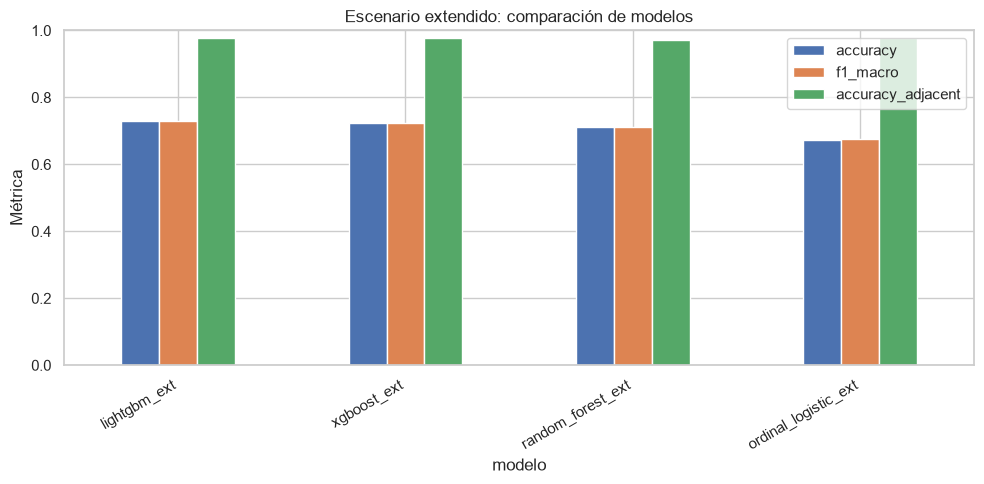

In [4]:
comparacion = pd.DataFrame(resultados).sort_values('f1_macro', ascending=False)
comparacion.to_csv(REPORTS_DIR / 'ext_comparacion_modelos.csv', index=False)
display(comparacion)

comparacion.set_index('modelo')[['accuracy', 'f1_macro', 'accuracy_adjacent']].plot(
    kind='bar', figsize=(10, 5)
)
plt.title('Escenario extendido: comparación de modelos')
plt.ylabel('Métrica')
plt.ylim(0, 1)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'ext_comparacion_modelos.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
mejor = comparacion.iloc[0]
resumen = {
    'mejor_modelo': mejor['modelo'],
    'accuracy': float(mejor['accuracy']),
    'f1_macro': float(mejor['f1_macro']),
    'accuracy_adjacent': float(mejor['accuracy_adjacent']),
    'qwk': float(mejor['qwk']),
}
print(json.dumps(resumen, indent=2, ensure_ascii=False))

with open(REPORTS_DIR / 'ext_mejor_modelo.json', 'w', encoding='utf-8') as archivo:
    json.dump(resumen, archivo, indent=2, ensure_ascii=False)

{
  "mejor_modelo": "lightgbm_ext",
  "accuracy": 0.7297414259439576,
  "f1_macro": 0.7288117290128767,
  "accuracy_adjacent": 0.9783620036784594,
  "qwk": 0.8593328822032051
}


## Lectura de resultados

- Comparar `accuracy` y `f1_macro` contra `reports/comparacion_base.csv` y `reports/comparacion_features.csv`.
- El escenario extendido no es estrictamente comparable con base/geo: añade variables y cambia el conjunto de features. Es el escenario de **mejor esfuerzo** para acercarse al 90 %.
- Si la accuracy exacta no llega a 0.90, revisar `accuracy_adjacent`: en un target ordinal de 4 clases, un acierto exacto o en la clase vecina suele ser la métrica que realmente importa al negocio.
- La importancia de variables y el tuning posterior indican qué variables nuevas aportan.